# Part 4 – Cancellation model

**Question.** How does the chance that a member cancels depend on the price they are charged? This model gives the tool its cancellation curve, $c(p)$, and answers whether the member discount pays.

**Findings** (details and checks below):

* **Price drives cancelling, causally.** Each \$1 more raises the log-odds of cancelling by 0.37 at \$12 (0.26 at \$7, 0.42 at \$14).

* **One model, no season effects.** Exposure this season and last carries most of each season's level. It is read as a marker of engagement, not as an effect of advertising.

* **Fit.** Within 0.9 pp of actual at every price, and within 2.5 pp in every season except winter 2019 (about 4 pp too high).

* **Rolling test.** Trained on earlier seasons only, summer and fall 2019 are within 1.1 pp; spring 2019 is 2.0–3.2 pp too high. The price curve is right in every season; the misses are in the level.

* **A \$1 member discount brings in the most.** Charging every member one price for four seasons, \$11 is best in both periods (\$34.00 per member before the cut, \$32.87 after), about \$2.41 more than today's random \$1–\$5 off after the cut. Deep discounts lose (\$25.82 at \$7). Full price is an extrapolation.

---

## 1. Setup

* **Unit.** One row per customer and season in the five cut regions, for customers who **were members last season**. `cancel` = 1 if they are not a member this season.
* **`price`**: this season's price, a fresh random \$1–\$5 off every season, recorded for cancellers too. So it is randomized for everyone at risk.
* **`price_lag`**: last season's price (the join price in a member's first season).
* **`tenure_lag`**: consecutive seasons as a member through last season; it restarts on rejoining.
* **`pod`, `soc`** (this season) and **`pod_last`, `soc_last`** (last season): podcast ad listens and social ad impressions.
* **Panem is excluded.** Its members always pay \$15, so there is no price variation to learn from.

In [13]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

import os, sys
if Path.cwd().name == 'analysis':
    os.chdir('..')
sys.path.insert(0, os.getcwd())

import helper.utils as u

u.apply_style()
CUT = u.CUT_T
BLUE, ORANGE, RUST = '#2a78d6', '#eb6834', '#b7410e'
SEASON_ORDER = {'winter': 0, 'spring': 1, 'summer': 2, 'fall': 3}

panel = u.load_panel('data/customer_panel.csv',
                     extra_cols=('customer_id', 'social_ad_impressions', 'podcast_ad_listen'))

In [14]:
df = (panel.sort_values(['customer_id', 't']).reset_index(drop=True)
           .rename(columns={'podcast_ad_listen': 'pod', 'social_ad_impressions': 'soc'}))
by_cust = df.groupby('customer_id')
df['prev_member'] = by_cust['sign_up_flag'].shift(1)
df['price_lag'] = by_cust['membership_price'].shift(1)
df['pod_last'], df['soc_last'] = by_cust['pod'].shift(1), by_cust['soc'].shift(1)      # last season's exposure
# Tenure: consecutive seasons as a member, restarting when someone rejoins
spell = (df['sign_up_flag'].eq(1) & df['prev_member'].fillna(0).eq(0)).groupby(df['customer_id']).cumsum()
df['tenure'] = np.where(df['sign_up_flag'].eq(1), df.groupby(['customer_id', spell]).cumcount() + 1, 0)
df['tenure_lag'] = df.groupby('customer_id')['tenure'].shift(1)

exposure = df[['customer_id', 't', 'pod', 'soc']]            # every customer, every season: used by the rolling test
d = (df[df['region_name'].ne(u.CONTROL) & df['prev_member'].eq(1)]
     .rename(columns={'membership_price': 'price'}).reset_index(drop=True))
d['cancel'] = 1 - d['sign_up_flag']
d['post'] = d['t'].ge(CUT).astype(int)
d['tenure_lag'] = d['tenure_lag'].astype(int)
d['tenure_group'] = d['tenure_lag'].clip(upper=8)
del panel, df

d = u.add_terms_cancel(d)
print(f"{len(d):,} member-seasons, {d['customer_id'].nunique():,} customers, cancel rate {d['cancel'].mean():.1%}")
display(d.groupby(['post', 'price'])['cancel'].agg(rows='size', cancel_rate='mean').reset_index().round(4))

# Randomization check: this season's price should be unrelated to everything else in the model
d.groupby(['post', 'price'])[['tenure_lag', 'price_lag', 'pod', 'soc', 'pod_last', 'soc_last']].mean().round(2)

587,701 member-seasons, 140,600 customers, cancel rate 14.2%


,post,price,rows,cancel_rate
0,0,10,63746,0.1158
1,0,11,63815,0.1448
2,0,12,63288,0.1822
3,0,13,63321,0.2334
4,0,14,63665,0.2902
5,1,7,54341,0.0506
6,1,8,53733,0.0626
7,1,9,53937,0.0779
8,1,10,53974,0.0959
9,1,11,53881,0.1214


tenure_lag  price_lag    pod   soc  pod_last  soc_last
post price                                                        
0    10           2.44      12.30  10.98  5.21     13.84      6.19
     11           2.45      12.29  10.95  5.24     13.80      6.18
     12           2.45      12.30  10.92  5.25     13.77      6.18
     13           2.45      12.30  10.92  5.23     13.86      6.20
     14           2.44      12.29  10.95  5.25     13.87      6.19
1    7            3.66      10.13   9.11  5.19     10.01      5.46
     8            3.66      10.14   9.14  5.19     10.02      5.47
     9            3.66      10.12   9.17  5.21      9.96      5.47
     10           3.66      10.14   9.17  5.21      9.98      5.47
     11           3.66      10.14   9.20  5.18     10.04      5.48

## 2. Modeling

$$\operatorname{logit} P(\text{cancel}_{it}) = \beta_1(\text{price}_{it}-12) + \beta_2(\text{price}_{it}-12)^2 + \beta_3(\text{price}_{i,t-1}-12) + \gamma_{\text{tenure}} + f(\text{exposure}_{it}) + g(\text{exposure}_{i,t-1}) + \mu_r$$

* `price_c`, `price_sq`: this season's price minus \$12, and its square. Causal.
* `lag_c`: last season's price minus \$12. Randomized too, but only members who stayed through it are observed, so it mixes carry-over with selection.
* $\gamma$: one dummy per tenure level (8 or more grouped). $f$, $g$: exposure this season and last, with the same terms as Part 3. $\mu_r$: region effects.
* **No season effects.** Standard errors are clustered by customer.

**Why exposure is in a cancellation model.** Heavily exposed members cancel far less (table below). This is read as engagement, not as ads keeping members: people who listen a lot hear more ads and get more from the service. It is what lets the model set a season's level without season effects.

In [15]:
# Cancel rate (%) by this season's price and this season's ad exposure
bands, labels = [-1, 0, 25, 80, 200, np.inf], ['none', '1-25', '26-80', '81-200', 'over 200']
band = pd.cut(d['pod_soc'], bands, labels=labels)
by_band = (100 * d.pivot_table(index=band, columns='price', values='cancel', observed=True)).round(1)
by_band.rename_axis('listens x impressions')

price,7,8,9,10,11,12,13,14
listens x impressions,,,,,,,,
none,14.1,17.2,20.6,24.5,29.0,35.3,41.5,47.1
1-25,5.9,7.4,9.2,14.8,18.0,26.7,32.8,39.6
26-80,2.2,2.9,4.0,7.3,10.4,15.9,22.1,28.9
81-200,0.0,0.3,0.4,0.8,1.5,3.0,5.4,9.4
over 200,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.1


In [16]:
THIS = ['pod', 'soc', 'sqrt_pod_soc', 'pod_soc', 'pod_zero', 'soc_zero']
LAST = ['pod_last', 'soc_last', 'sqrt_pod_soc_last', 'pod_soc_last', 'pod_zero_last', 'soc_zero_last']
RHS = 'lag_c + C(tenure_group) + ' + ' + '.join(THIS + LAST) + ' + C(region_name)'
FORMULA = 'cancel ~ price_c + price_sq + ' + RHS

final = u.fit_logit(FORMULA, d)
terms = ['price_c', 'price_sq', 'lag_c', *THIS, *LAST]
ci = final.conf_int()

display(pd.DataFrame({'estimate': final.params[terms], 'ci_low': ci.loc[terms, 0], 'ci_high': ci.loc[terms, 1],
                      'p_value': final.pvalues[terms]}).round(4))

slope_at = lambda p: final.params['price_c'] + 2 * final.params['price_sq'] * (p - 12)
display(final.params.filter(like='tenure_group').rename(lambda s: s.split('T.')[1].rstrip(']')).rename('log-odds vs 1 season')
        .round(3).to_frame().T.rename_axis('seasons as a member (8 = 8 or more)', axis=1))

,estimate,ci_low,ci_high,p_value
price_c,0.3721,0.3660,0.3781,0.0000
price_sq,0.0117,0.0097,0.0136,0.0000
lag_c,0.1844,0.1797,0.1891,0.0000
pod,-0.0013,-0.0032,0.0006,0.1691
soc,0.0157,0.0118,0.0195,0.0000
sqrt_pod_soc,0.1056,0.0919,0.1193,0.0000
pod_soc,-0.0328,-0.0339,-0.0317,0.0000
pod_zero,0.3962,0.3545,0.4380,0.0000
soc_zero,0.2459,0.2043,0.2876,0.0000
pod_last,0.0062,0.0040,0.0084,0.0000


seasons as a member (8 = 8 or more),2,3,4,5,6,7,8
log-odds vs 1 season,-1.047,-1.142,-1.161,-1.182,-1.025,-1.139,-1.125


**Reading**

* **Price:** +0.37 log-odds per \$1 at \$12 (0.26 at \$7, 0.42 at \$14).

* **Last season's price:** +0.18 per \$1, carry-over mixed with selection.

* **Tenure:** after their first season, members cancel much less (−1.0 to −1.2 log-odds), with no further trend.

* **Exposure:** heavier exposure, this season or last, goes with much less cancelling (table above).

## 3. Validation

In [17]:
# 3.1 Calibration: actual vs predicted cancel rate, all seasons
d['p_hat'] = final.predict(d)


def gaps(by):
    out = d.groupby(by).agg(rows=('cancel', 'size'), actual=('cancel', 'mean'), predicted=('p_hat', 'mean'))
    out['gap_pp'] = 100 * (out['actual'] - out['predicted'])
    return out
    
cal, cal_t = gaps(['post', 'price']), gaps('t').rename(index=u.period_label)
display(cal.round(4))
display((100 * cal_t[['actual', 'predicted']]).round(1).T)

rows  actual  predicted  gap_pp
post price                                  
0    10     63746  0.1158     0.1083  0.7520
     11     63815  0.1448     0.1403  0.4492
     12     63288  0.1822     0.1809  0.1335
     13     63321  0.2334     0.2316  0.1780
     14     63665  0.2902     0.2915 -0.1256
1    7      54341  0.0506     0.0501  0.0429
     8      53733  0.0626     0.0625  0.0001
     9      53937  0.0779     0.0794 -0.1536
     10     53974  0.0959     0.1021 -0.6244
     11     53881  0.1214     0.1305 -0.9035

t,Spr 2017,Sum 2017,Fall 2017,Win 2018,Spr 2018,Sum 2018,Fall 2018,Win 2019,Spr 2019,Sum 2019,Fall 2019
actual,28.7,22.8,23.4,22.4,29.1,17.4,14.7,11.5,8.3,9.2,7.2
predicted,28.3,21.3,22.7,20.2,26.6,16.3,14.0,15.7,9.3,9.8,6.7


In [18]:
# 3.2 Checks on the price terms and on leaving out season effects
dummies = u.fit_logit('cancel ~ C(price) + ' + RHS, d)
lr, dof = 2 * (dummies.llf - final.llf), dummies.df_model - final.df_model
print(f"Price dummies vs quadratic: LR = {lr:.1f} on {dof:.0f} df, p = {stats.chi2.sf(lr, dof):.2f}")
at_cut = u.fit_logit(FORMULA + ' + price_post', d.assign(price_post=d['price_c'] * d['post']))
print(f"Separate price slope after the cut: {at_cut.params['price_post']:+.3f}, LR = {2 * (at_cut.llf - final.llf):.1f} on 1 df")
with_t = u.fit_logit(FORMULA + ' + C(t)', d)
no_exposure = u.fit_logit('cancel ~ price_c + price_sq + lag_c + C(tenure_group) + C(region_name) + C(t)', d)
spread = lambda m: m.params.filter(like='C(t)').max() - m.params.filter(like='C(t)').min()
print(f"Spread of season effects if added: {spread(no_exposure):.2f} log-odds without the exposure terms, "
      f"{spread(with_t):.2f} with them")
del dummies, at_cut, with_t, no_exposure

Price dummies vs quadratic: LR = 10.9 on 5 df, p = 0.05
Separate price slope after the cut: +0.091, LR = 117.6 on 1 df
Spread of season effects if added: 1.13 log-odds without the exposure terms, 0.70 with them


In [19]:
# 3.3 Rolling test on the three post-cut seasons: train on every season before k, then predict season k.
#     Last season's exposure is known by then. This season's is not, so each member is given their own
#     exposure from the earlier season whose planned podcast and social spend was closest.
spend = pd.read_csv('data/aggregate.csv')
spend['t'] = (spend['year'] - u.FIRST_YEAR) * 4 + spend['season'].map(u.SEASONS)
log_spend = np.log(spend.groupby('t')[['podcast_spend', 'social_spend']].first())

parts = []
for k in sorted(d.loc[d['post'].eq(1), 't'].unique()):
    train = d[d['t'].lt(k)]
    m = u.match_season(k, sorted(train['t'].unique()), log_spend)
    fit_k = u.fit_logit(FORMULA, train)
    x = u.with_exposure_from(d[d['t'].eq(k)], m, exposure, add_terms=u.add_terms_cancel)
    x['predicted'] = fit_k.predict(x)
    parts.append(x[['t', 'price', 'cancel', 'predicted']].assign(trained_through=k - 1, matched=m))
    del fit_k
roll = pd.concat(parts)

oot = roll.groupby(['t', 'trained_through', 'matched', 'price']).agg(actual=('cancel', 'mean'), predicted=('predicted', 'mean'))
oot['gap_pp'] = 100 * (oot['actual'] - oot['predicted'])

by_season = oot['gap_pp'].abs().groupby(level='t').max().rename(index=u.period_label)

pooled = (100 * roll.groupby('price').agg(actual=('cancel', 'mean'), predicted=('predicted', 'mean'))).round(1)
display(pooled.T.rename_axis('three seasons together, %'))
label = lambda col: (lambda x: x[col].map(u.period_label))
((100 * oot[['actual', 'predicted']]).round(1).assign(gap_pp=oot['gap_pp'].round(1)).reset_index()
    .assign(t=label('t'), trained_through=label('trained_through'), matched=label('matched'))
    .rename(columns={'t': 'season', 'trained_through': 'trained through', 'matched': 'exposure matched to',
                     'actual': 'actual %', 'predicted': 'predicted %'}))

price,7,8,9,10,11
"three seasons together, %",,,,,
actual,5.1,6.3,7.8,9.6,12.1
predicted,5.0,6.2,7.9,10.0,12.8


,season,trained through,exposure matched to,price,actual %,predicted %,gap_pp
0,Spr 2019,Win 2019,Spr 2018,7,5.0,7.1,-2.1
1,Spr 2019,Win 2019,Spr 2018,8,6.4,8.4,-2.0
2,Spr 2019,Win 2019,Spr 2018,9,7.7,10.3,-2.6
3,Spr 2019,Win 2019,Spr 2018,10,9.9,12.6,-2.7
4,Spr 2019,Win 2019,Spr 2018,11,12.6,15.8,-3.2
5,Sum 2019,Spr 2019,Sum 2017,7,5.6,4.7,0.9
6,Sum 2019,Spr 2019,Sum 2017,8,7.0,6.1,0.9
7,Sum 2019,Spr 2019,Sum 2017,9,8.8,8.0,0.8
8,Sum 2019,Spr 2019,Sum 2017,10,10.6,10.5,0.1
9,Sum 2019,Spr 2019,Sum 2017,11,13.9,13.7,0.1


**Reading: fit**

* **By price:** within 0.9 pp. A little low at \$10 before the cut (0.8 pp) and a little high at \$10–\$11 after it (0.6–0.9 pp).

* **By season:** within 2.5 pp in ten of eleven seasons. Winter 2019 is about 4 pp too high (15.7% against 11.5%).

* **Price shape:** the quadratic is borderline against one dummy per price (p = 0.05). The slope differs slightly after the cut (+0.09 log-odds, LR = 117.6), small next to 0.37.

* **Season effects are reduced, not removed:** their spread is 0.70 log-odds with exposure, against 1.13 without.

**Reading: rolling test** (each post-cut season predicted from earlier seasons, with this season's exposure borrowed from the earlier season with the closest planned spend)

* **Summer and fall 2019** are within 0.9 pp and 1.1 pp at every price.

* **Spring 2019,** the first season at the new prices, is 2.0–3.2 pp too high.

* **All three together** are within 0.7 pp at every price. The slope is right in every season; the misses are in the level.

* **Taken as given:** who is a member each season, their tenure and last season's price.

## 4. Revenue per member

**Each scenario charges every member price $p$ for four seasons.** Revenue per member is each season's price times the probability the member is still there, summed:

$$V = \sum_{t=1}^{4} p_t \cdot P(\text{member in season } t), \qquad P(\text{member in season } t) = \prod_{k=1}^{t} \big(1 - c_k\big),$$

where $c_k$ is the model's cancel rate in season $k$, given that season's price, last season's price, tenure and exposure.

* **Season 1** uses each member's actual last price (today's random \$1–\$5 off), so it rests on the causal price terms.
* **Seasons 2–4** add one season of tenure and set last season's price to $p$, so they lean on the last-price coefficient.
* **Exposure** is held at each member's observed levels. **Today's policy** runs through the same steps, with a fresh random \$1–\$5 off each season.
* **Full price** (\$15 before the cut, \$12 after) was never charged to members, so those rows extend the model one dollar beyond the data.

In [20]:
# 4.1 Revenue per member if every member is charged one price for the next four seasons.
#     Season 1: last season's price as observed (today's random $1-$5 off). Seasons 2-4: tenure + 1 each season
#     and last season's price = p. Survival is compounded member by member, then averaged.
SEASONS_AHEAD = 4
rows = []
for flag, base in [(0, 15), (1, 12)]:
    members = d[d['post'].eq(flag)]
    for p in range(base - 5, base + 1):
        x = members.assign(price=p)
        stay, revenue = np.ones(len(x)), np.zeros(len(x))
        for k in range(1, SEASONS_AHEAD + 1):
            c = final.predict(u.add_terms_cancel(x)).to_numpy()
            if k == 1:
                first_season = c.mean()
            stay *= 1 - c                                          # still a member after season k
            revenue += p * stay
            x = x.assign(tenure_group=np.minimum(x['tenure_group'] + 1, 8), price_lag=p)
        rows.append({'period': 'post-cut' if flag else 'pre-cut', 'member price': p, 'discount': base - p,
                     'cancel rate': first_season, 'revenue per member, 4 seasons': revenue.mean(),
                     'in the data': p < base})
del x
member_value = pd.DataFrame(rows).set_index(['period', 'member price'])

# Today's policy as the baseline: a fresh random $1-$5 off every season, so last season's price is the previous draw.
rng = np.random.default_rng(0)
today = {}
for flag, base in [(0, 15), (1, 12)]:
    x = d[d['post'].eq(flag)]
    stay, revenue = np.ones(len(x)), np.zeros(len(x))
    for k in range(1, SEASONS_AHEAD + 1):
        p = rng.integers(base - 5, base, len(x))                 # base - $5 ... base - $1, one draw per member
        x = x.assign(price=p)
        stay *= 1 - final.predict(u.add_terms_cancel(x)).to_numpy()
        revenue += p * stay
        x = x.assign(tenure_group=np.minimum(x['tenure_group'] + 1, 8), price_lag=p)
    today['post-cut' if flag else 'pre-cut'] = revenue.mean()
del x
print("Today's policy (random $1-$5 off, re-drawn each season), revenue per member over 4 seasons: "
      + ', '.join(f'{k} ${v:.2f}' for k, v in today.items()))
member_value.round(3)

Today's policy (random $1-$5 off, re-drawn each season), revenue per member over 4 seasons: pre-cut $32.75, post-cut $30.46


discount  cancel rate  revenue per member, 4 seasons  \
period   member price                                                         
pre-cut  10                   5        0.109                         33.184   
         11                   4        0.140                         34.003   
         12                   3        0.181                         33.699   
         13                   2        0.231                         32.237   
         14                   1        0.292                         29.779   
         15                   0        0.362                         26.623   
post-cut 7                    5        0.050                         25.817   
         8                    4        0.063                         28.673   
         9                    3        0.079                         30.957   
         10                   2        0.102                         32.436   
         11                   1        0.131                         32.870   
         12                   0        0.169                         32.110   

                       in the data  
period   member price               
pre-cut  10                   True  
         11                   True  
         12                   True  
         13                   True  
         14                   True  
         15                  False  
post-cut 7                    True  
         8                    True  
         9                    True  
         10                   True  
         11                   True  
         12                  False

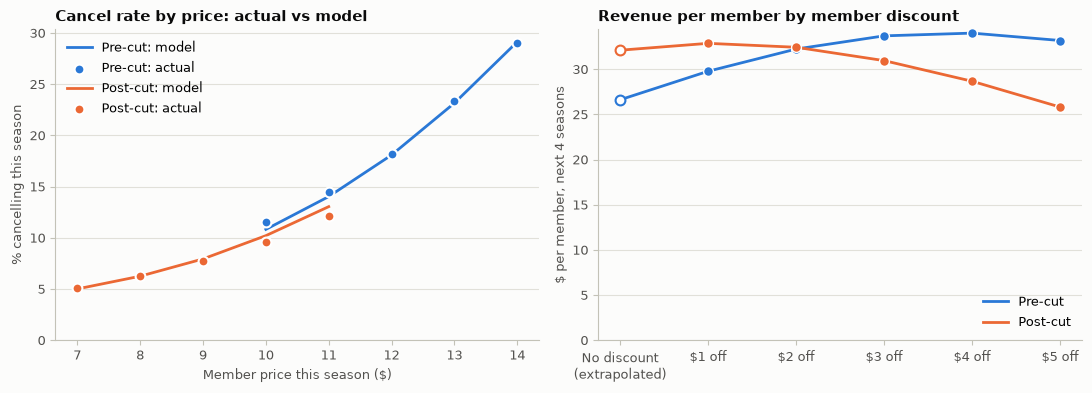

In [21]:
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
for (flag, name), color in zip([(0, 'Pre-cut'), (1, 'Post-cut')], [BLUE, ORANGE]):
    c, v = cal.loc[flag], member_value.loc[name.lower()]
    left.plot(c.index, 100 * c['predicted'], color=color, lw=2, label=f'{name}: model')
    left.scatter(c.index, 100 * c['actual'], s=50, color=color, edgecolor='white', linewidth=1.5, zorder=3,
                 label=f'{name}: actual')
    right.plot(v['discount'], v['revenue per member, 4 seasons'], color=color, lw=2, label=name)
    seen, extra = v[v['in the data']], v[~v['in the data']]
    right.scatter(seen['discount'], seen['revenue per member, 4 seasons'], s=50, color=color, edgecolor='white', zorder=3)
    right.scatter(extra['discount'], extra['revenue per member, 4 seasons'], s=50, facecolor='white', edgecolor=color,
                  linewidth=1.5, zorder=3)
left.set_xticks(range(7, 15))
left.set_ylim(0, None)
left.set_xlabel('Member price this season ($)')
left.set_ylabel('% cancelling this season')
left.set_title('Cancel rate by price: actual vs model', loc='left')
left.legend(frameon=False)
right.set_xticks(range(6), ['No discount\n(extrapolated)'] + [f'${k} off' for k in range(1, 6)])
right.set_ylim(0, None)
right.set_ylabel('$ per member, next 4 seasons')
right.set_title('Revenue per member by member discount', loc='left')
right.legend(frameon=False, loc='lower right')
fig.tight_layout()
plt.show()

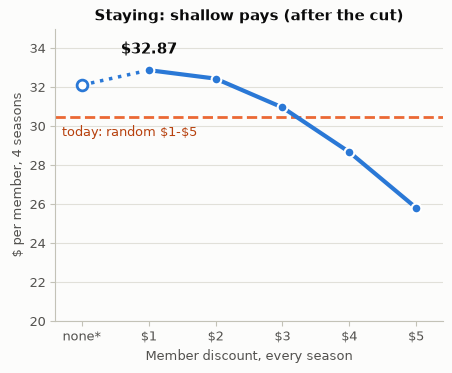

In [22]:
# Figure 2, right panel (write-up)

v = member_value.loc['post-cut'].set_index('discount').sort_index()['revenue per member, 4 seasons']
fig, ax = plt.subplots(figsize=(5, 3.8))
ax.plot(v.index[:2], v.iloc[:2], color=BLUE, lw=2.5, ls=':')                          # full price is extrapolated
ax.plot(v.index[1:], v.iloc[1:], color=BLUE, lw=3, marker='o', ms=7, mec='white', mew=1.5, zorder=3)
ax.scatter(0, v.loc[0], s=60, facecolor='white', edgecolor=BLUE, linewidth=2, zorder=4)
best = v.idxmax()
ax.annotate(f'\\${v[best]:.2f}', (best, v[best]), xytext=(0, 12), textcoords='offset points', ha='center',
            fontsize=11, weight='bold', color=u.INK)
ax.axhline(today['post-cut'], color=ORANGE, lw=2, ls='--')
ax.text(-0.3, today['post-cut'] - 0.4, 'today: random \\$1-\\$5', ha='left', va='top', fontsize=9, color=RUST)
ax.set_xticks(range(6), ['none*'] + [f'\\${k}' for k in range(1, 6)])
ax.set_xlim(-0.4, 5.4)
ax.set_ylim(20, 35)
ax.set_xlabel('Member discount, every season')
ax.set_ylabel('\\$ per member, 4 seasons')
ax.set_title('Staying: shallow pays (after the cut)', loc='center')
plt.show()


**Reading**

* **\$11 is best in both periods:** \$34.00 per member before the cut (\$33.70 at \$12, \$33.18 at \$10) and \$32.87 after (\$32.44 at \$10, \$32.11 at \$12).

* **Deep discounts and full price lose.** \$7 brings in \$25.82 after the cut; \$15 brings in \$26.62 before it, with 36% cancelling in the first season.

* **Against today's policy** (\$30.46 per member after the cut, \$32.75 before), charging every member \$11 adds about \$2.41 over four seasons (\$1.25 before).

* **\$11 against \$12 is close** (0.9% before the cut, 2.4% after). \$12 is an extrapolation and seasons 2–4 lean on the last-price term, so the safe reading is a small member discount, not a deep one.

In [23]:
out = Path('outputs')
out.mkdir(exist_ok=True)
final.params.rename('coefficient').to_csv(out / 'cancel_model_params.csv')
member_value.to_csv(out / 'member_value_by_price.csv')
oot.to_csv(out / 'cancel_rolling_test.csv')